Dataset shape: (2823, 25)
   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue

,CUSTOMERNAME,TotalSales,TotalQuantity,NumberOfOrders,AveragePrice,AverageOrderValue
0,"AV Stores, Co.",157807.81,1778,3,77.947647,52602.603333
1,Alpha Cognac,70488.44,687,3,85.097500,23496.146667
2,Amica Models & Co.,94117.26,843,2,85.323462,47058.630000
3,"Anna's Decorations, Ltd",153996.13,1469,4,83.558043,38499.032500
4,Atelier graphique,24179.96,270,3,79.775714,8059.986667


Scaled feature shape: (92, 5)


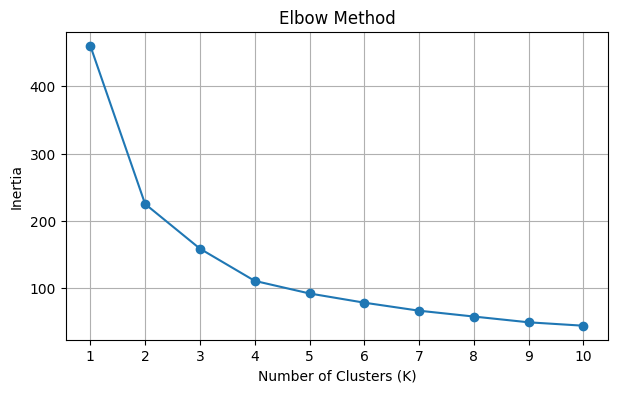

KMeans_Cluster
0    32
1     2
2    25
3    33
Name: count, dtype: int64


,CUSTOMERNAME,TotalSales,TotalQuantity,NumberOfOrders,AveragePrice,AverageOrderValue,KMeans_Cluster
0,"AV Stores, Co.",157807.81,1778,3,77.947647,52602.603333,3
1,Alpha Cognac,70488.44,687,3,85.097500,23496.146667,0
2,Amica Models & Co.,94117.26,843,2,85.323462,47058.630000,3
3,"Anna's Decorations, Ltd",153996.13,1469,4,83.558043,38499.032500,3
4,Atelier graphique,24179.96,270,3,79.775714,8059.986667,2


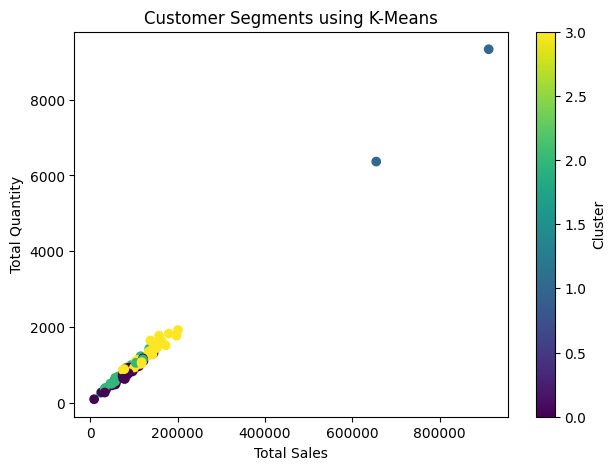

Hierarchical_Cluster
0    37
1     2
2    34
3    19
Name: count, dtype: int64


,CUSTOMERNAME,KMeans_Cluster,Hierarchical_Cluster
0,"AV Stores, Co.",3,0
1,Alpha Cognac,0,3
2,Amica Models & Co.,3,0
3,"Anna's Decorations, Ltd",3,0
4,Atelier graphique,2,3
5,"Australian Collectables, Ltd",2,2
6,"Australian Collectors, Co.",3,0
7,"Australian Gift Network, Co",0,3
8,Auto Assoc. & Cie.,2,2
9,Auto Canal Petit,2,2


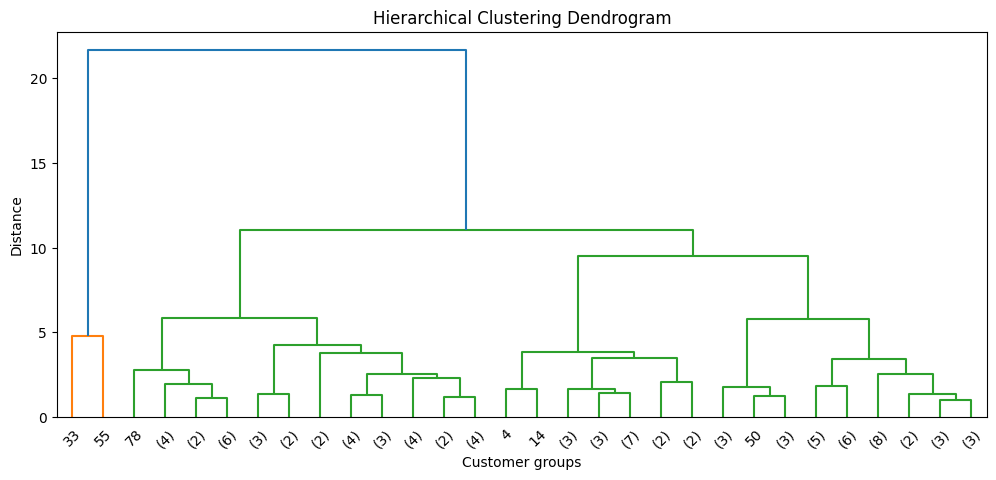

K-Means silhouette score: 0.31894702282157683
Hierarchical silhouette score: 0.2954137056551451


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

     
#Cell 2 – Load and inspect dataset

from pathlib import Path

import pandas as pd

# Load CSV from the same folder as the notebook
DATA_PATH = "sales_data_sample.csv.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print(df.head())
print("Columns:", df.columns.tolist())

     
#Cell 3 – Clean required columns and create customer-level data

required_columns = [
    "CUSTOMERNAME", "ORDERNUMBER", "QUANTITYORDERED",
    "SALES", "PRICEEACH"
]

sales = df[required_columns].copy()

sales["QUANTITYORDERED"] = pd.to_numeric(
    sales["QUANTITYORDERED"], errors="coerce"
)
sales["SALES"] = pd.to_numeric(sales["SALES"], errors="coerce")
sales["PRICEEACH"] = pd.to_numeric(sales["PRICEEACH"], errors="coerce")

sales = sales.dropna(subset=["CUSTOMERNAME", "ORDERNUMBER", "QUANTITYORDERED", "SALES"])

# One row per customer, created by aggregating their transactions.
customer_data = sales.groupby("CUSTOMERNAME").agg(
    TotalSales=("SALES", "sum"),
    TotalQuantity=("QUANTITYORDERED", "sum"),
    NumberOfOrders=("ORDERNUMBER", "nunique"),
    AveragePrice=("PRICEEACH", "mean")
).reset_index()

customer_data["AverageOrderValue"] = (
    customer_data["TotalSales"] / customer_data["NumberOfOrders"]
)

customer_data = customer_data.replace([np.inf, -np.inf], np.nan).dropna()

print("Number of customers:", len(customer_data))
display(customer_data.head())

     
#Cell 4 – Select features and scale them

features = [
    "TotalSales", "TotalQuantity",
    "NumberOfOrders", "AveragePrice", "AverageOrderValue"
]

X = customer_data[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled feature shape:", X_scaled.shape)

     
#Cell 5 – Find the number of clusters using Elbow Method

inertia_values = []
max_k = min(10, len(customer_data) - 1)

for k in range(1, max_k + 1):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia_values.append(kmeans.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(range(1, max_k + 1), inertia_values, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(range(1, max_k + 1))
plt.grid(True)
plt.show()

     
#Cell 6 – Apply K-Means clustering

# Choose K by observing the elbow in the plot.
# Four clusters are used as a starting value; change it if your elbow suggests otherwise.
chosen_k = 4

kmeans_model = KMeans(
    n_clusters=chosen_k, random_state=42, n_init=10
)
customer_data["KMeans_Cluster"] = kmeans_model.fit_predict(X_scaled)

print(customer_data["KMeans_Cluster"].value_counts().sort_index())
display(customer_data.head())

     
#Cell 7 – Visualize K-Means clusters

plt.figure(figsize=(7, 5))
scatter = plt.scatter(
    customer_data["TotalSales"],
    customer_data["TotalQuantity"],
    c=customer_data["KMeans_Cluster"]
)
plt.xlabel("Total Sales")
plt.ylabel("Total Quantity")
plt.title("Customer Segments using K-Means")
plt.colorbar(scatter, label="Cluster")
plt.show()

     
#Cell 8 – Apply Hierarchical clustering

hierarchical_model = AgglomerativeClustering(n_clusters=chosen_k)
customer_data["Hierarchical_Cluster"] = hierarchical_model.fit_predict(X_scaled)

print(customer_data["Hierarchical_Cluster"].value_counts().sort_index())
display(customer_data[[
    "CUSTOMERNAME", "KMeans_Cluster", "Hierarchical_Cluster"
]].head(10))

     
#Cell 9 – Draw a dendrogram

# Dendrogram is displayed for the customer observations in this dataset.
linked = linkage(X_scaled, method="ward")

plt.figure(figsize=(12, 5))
dendrogram(linked, truncate_mode="lastp", p=30)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Customer groups")
plt.ylabel("Distance")
plt.show()

     
#Cell 10 – Compare cluster quality

if len(set(customer_data["KMeans_Cluster"])) > 1:
    print(
        "K-Means silhouette score:",
        silhouette_score(X_scaled, customer_data["KMeans_Cluster"])
    )

if len(set(customer_data["Hierarchical_Cluster"])) > 1:
    print(
        "Hierarchical silhouette score:",
        silhouette_score(X_scaled, customer_data["Hierarchical_Cluster"]))

In [ ]:
# errors="coerce" converts invalid values into NaN instead of generating an error.
# groupby() groups records based on a common value.
# The Elbow Method is a technique used to determine the optimal number of clusters (K) in K-Means clustering.

# It works by calculating the inertia for different values of K.
# There are two types:
# 1. Agglomerative clustering – Bottom-up approach.
# 2. Divisive clustering – Top-down approach.
# A dendrogram is a tree-like diagram that represents how clusters are merged at different distance levels in hierarchical clustering.
# What is Silhouette Score?

# It measures how well each data point fits within its assigned cluster compared with other clusters.






# "In this experiment, I have implemented K-Means and Agglomerative Hierarchical Clustering on a sales dataset to perform customer segmentation.

# First, I loaded the dataset using Pandas and selected the required columns.

# Then, I performed data cleaning and grouped the transaction records customer-wise using groupby and aggregation functions.

# I calculated customer-level features such as Total Sales, Total Quantity, Number of Orders, Average Price and Average Order Value.

# After that, I applied StandardScaler to bring all features to a comparable scale.

# Next, I used the Elbow Method to determine a suitable number of clusters by calculating inertia for different K values.

# I applied K-Means clustering and visualized the resulting customer segments using a scatter plot.

# I also implemented Agglomerative Hierarchical Clustering and visualized the cluster hierarchy using a dendrogram.

# Finally, I compared both algorithms using the Silhouette Score."